# TALLER 1 TAM
Nombres:
# Marlyn Nathalia Mora Riascos y
# Hernan Jair Telpiz Cuaran

# 1.1

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

#definimos los parametros
w= np.array([1,2])
b= -3


#PUNTOS A EVALUAR
x1 =np.array([0,0])
x2 =np.array([1,0])
x3 =np.array([2,1])
x4 =np.array([3,1])

#guardamos los puntos en una lista para evaluar
puntos={"X1":x1, "X2":x2,"X3":x3, "X4": x4}

#Evaluacion a cada punto
for x in puntos.values():
  resultado=np.dot(w,x)+b
  clase= "+1" if resultado > 0 else "-1"
  print(f"Punto {x} -> w^T*x + b = {resultado} -> Clase: {clase}")

Punto [0 0] -> w^T*x + b = -3 -> Clase: -1
Punto [1 0] -> w^T*x + b = -2 -> Clase: -1
Punto [2 1] -> w^T*x + b = 1 -> Clase: +1
Punto [3 1] -> w^T*x + b = 2 -> Clase: +1


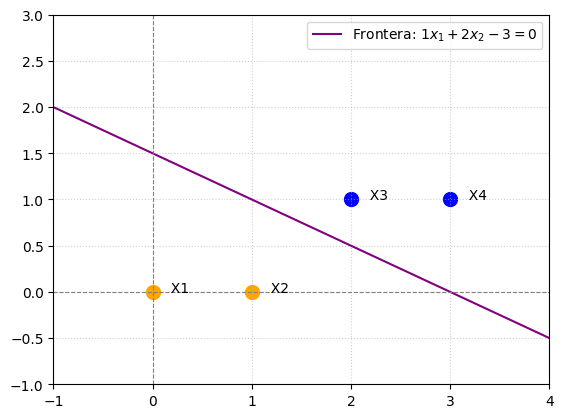

In [ ]:
# Genera 100 valores equiespaciados para el eje x1 (desde -1 hasta 4)
x1_vals = np.linspace(-1, 4, 100)

# Dibuja la línea de la frontera de decisión despejando x2 de la ecuación: w[0]*x1 + w[1]*x2 + b = 0
plt.plot(
    x1_vals,
    (-w[0] * x1_vals - b) / w[1],
    color="purple",
    label="Frontera: $1x_1 + 2x_2 - 3 = 0$",
)

# Recorre el diccionario de puntos para dibujarlos uno a uno
for nombre, v in puntos.items():
    # Asigna el color azul si el punto está en el lado positivo de la frontera, o naranja si está en el negativo
    color = "blue" if np.dot(w, v) + b > 0 else "orange"

    # Dibuja el punto en sus coordenadas (v[0], v[1]) con el color definido y tamaño 100
    plt.scatter(v[0], v[1], color=color, s=100)

    # Añade el nombre (etiqueta) del punto al lado de su ubicación en el gráfico
    plt.text(v[0] + 0.1, v[1], f"  {nombre}")

# Dibuja las líneas de los ejes X e Y en color gris y estilo discontinuo
plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
plt.axvline(0, color="gray", linestyle="--", linewidth=0.8)

# Define los límites visuales para los ejes horizontal y vertical
plt.xlim(-1, 4)
plt.ylim(-1, 3)

# Muestra la leyenda configurada en el gráfico
plt.legend()

# Añade una cuadrícula de fondo con líneas punteadas y semi-transparentes
plt.grid(True, linestyle=":", alpha=0.6)

# Renderiza y muestra la gráfica resultante en pantalla
plt.show()

# 2.2

k= 1 | Train: 1.0000 | Test: 0.9333
k= 5 | Train: 0.9571 | Test: 0.9556
k=15 | Train: 0.9571 | Test: 0.9333


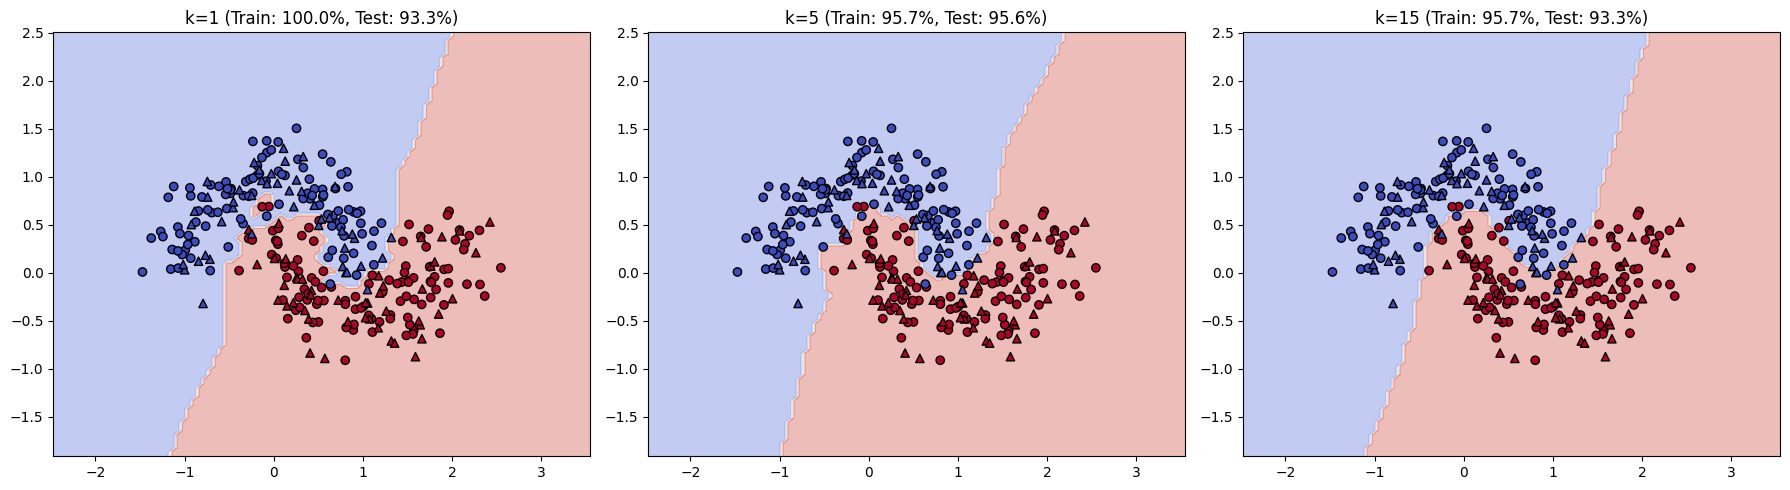

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_moons
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

# 1. Datos y división (70/30 estratificado)
X, y = make_moons(n_samples=300, noise=0.2, random_state=42)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# 2. Entrenamiento, reporte y gráfica en un solo bucle
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, k in zip(axes, [1, 5, 15]):
  clf = KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr)

  # Imprimir exactitudes en consola
  print(
      f"k={k:2d} | Train: {clf.score(X_tr, y_tr):.4f} | Test:"
      f" {clf.score(X_te, y_te):.4f}"
  )

  # Graficar regiones de decisión y puntos
  DecisionBoundaryDisplay.from_estimator(
      clf, X, response_method="predict", cmap=plt.cm.coolwarm, alpha=0.35, ax=ax
  )
  ax.scatter(X_tr[:, 0], X_tr[:, 1], c=y_tr, cmap=plt.cm.coolwarm, edgecolors="k")
  ax.scatter(
      X_te[:, 0],
      X_te[:, 1],
      c=y_te,
      cmap=plt.cm.coolwarm,
      marker="^",
      edgecolors="k",
  )
  ax.set_title(
      f"k={k} (Train: {clf.score(X_tr, y_tr):.1%}, Test:"
      f" {clf.score(X_te, y_te):.1%})"
  )

plt.tight_layout()
plt.show()

# 3.3

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

# 1. Etiquetas verdaderas (y) y predicciones (y_pred) dadas en el enunciado
y_true = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1])
y_pred = np.array([0, 1, 0, 0, 1, 0, 1, 1, 0, 1])

# 2. Verificación de resultados usando scikit-learn
print("--- MATRIZ DE CONFUSIÓN ---")
print(confusion_matrix(y_true, y_pred))

print("\n--- MÉTRICAS DE EVALUACIÓN ---")
print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
print(f"Precision: {precision_score(y_true, y_pred):.4f}")
print(f"Recall:    {recall_score(y_true, y_pred):.4f}")
print(f"F1-score:  {f1_score(y_true, y_pred):.4f}")

--- MATRIZ DE CONFUSIÓN ---
[[3 1]
 [2 4]]

--- MÉTRICAS DE EVALUACIÓN ---
Accuracy:  0.7000
Precision: 0.8000
Recall:    0.6667
F1-score:  0.7273
